--- Dataset Info ---
<class 'pandas.DataFrame'>
Index: 740 entries, 0 to 753
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Region                                   740 non-null    str    
 1   Date                                     740 non-null    str    
 2   Frequency                                740 non-null    str    
 3   Estimated Unemployment Rate (%)          740 non-null    float64
 4   Estimated Employed                       740 non-null    float64
 5   Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                     740 non-null    str    
dtypes: float64(3), str(4)
memory usage: 70.2 KB
None

--- Missing Values ---
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Est

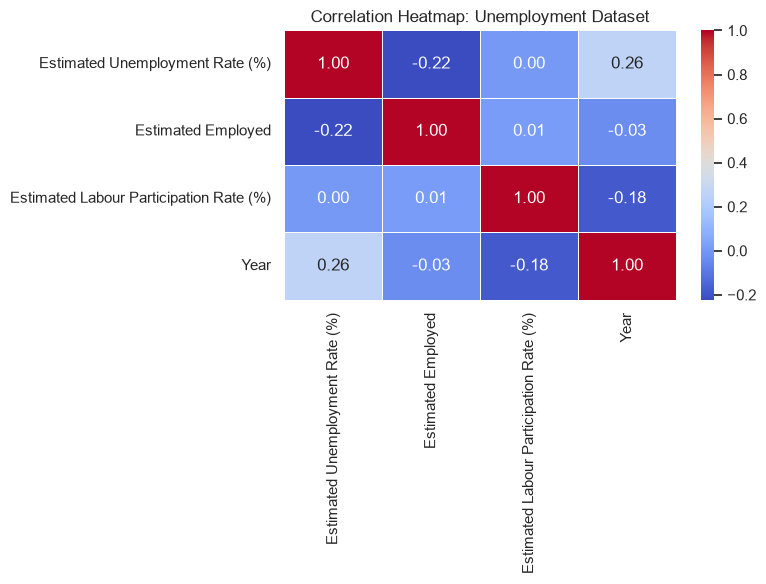

C:\Users\admin46\AppData\Local\Temp\ipykernel_15116\43299883.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


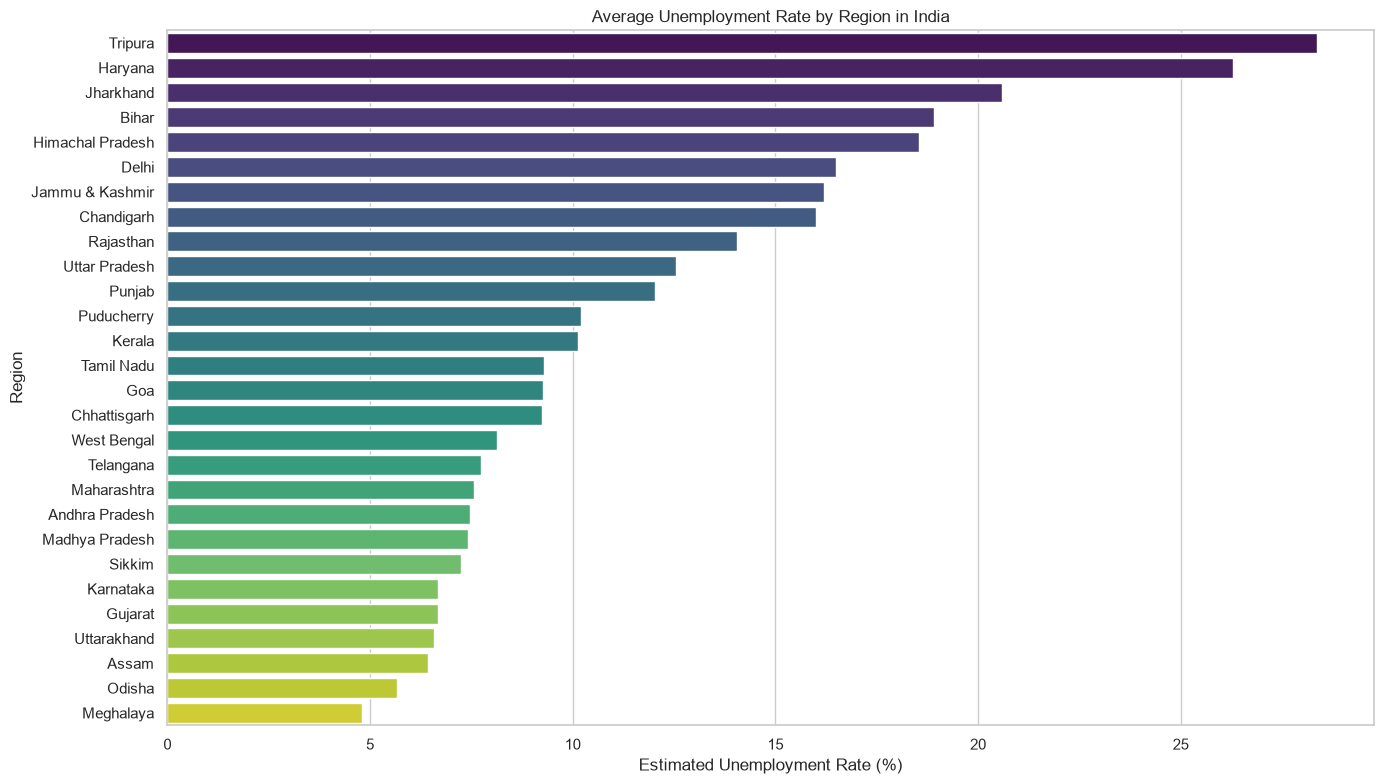

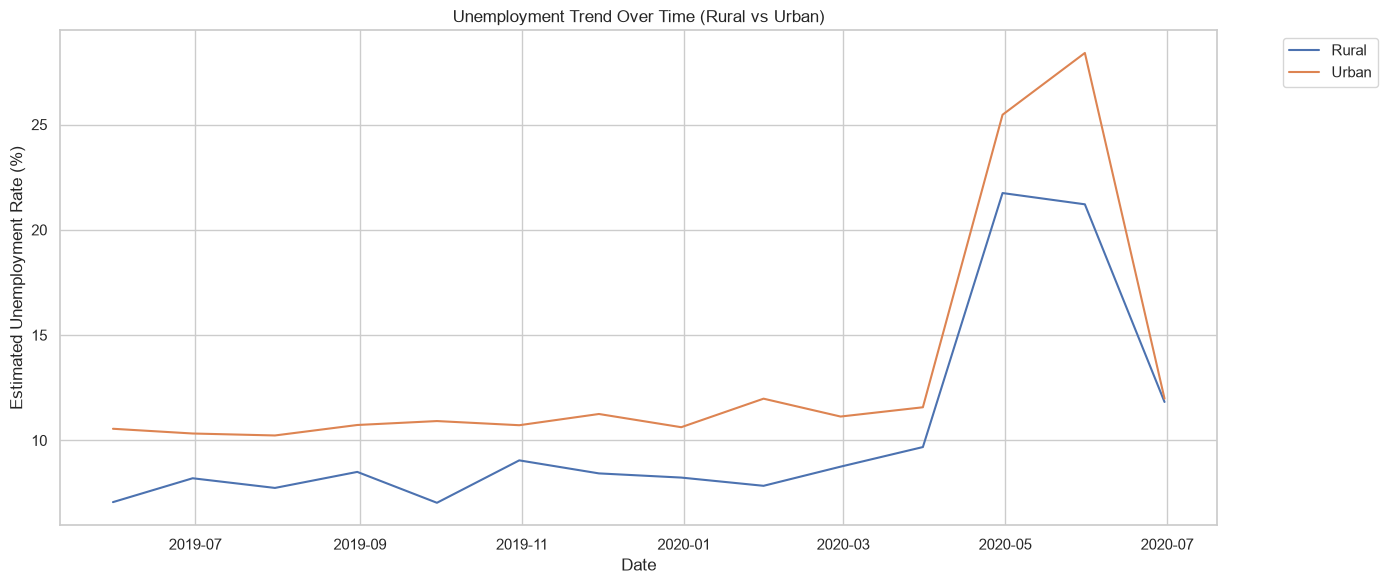

In [4]:
# Import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set style for visualizations
sns.set_theme(style="whitegrid")

# 1. Load the dataset using your exact folder path
file_path = r"C:\Users\admin46\OneDrive\studies\grow\OIBSIP\DataScienece-Task2-Unemployment_Analysis\Unemployment in India.csv"
df = pd.read_csv(file_path)

# Clean column names (strip trailing/leading spaces)
df.columns = df.columns.str.strip()

# Drop any completely empty rows
df = df.dropna(how="all")

# 2. Data Cleaning & Inspection
print("--- Dataset Info ---")
print(df.info())

print("\n--- Missing Values ---")
print(df.isnull().sum())

# Convert Date column to datetime format
df["Date"] = pd.to_datetime(df["Date"].str.strip(), dayfirst=True)

# Extract Month and Year for time-based analysis
df["Month"] = df["Date"].dt.month_name()
df["Year"] = df["Date"].dt.year

# 3. Exploratory Data Analysis (EDA)
print("\n--- Summary Statistics ---")
print(df.describe())

# Group by Region to find average unemployment rates
regional_unemployment = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"].mean().reset_index()
)
print("\n--- Average Unemployment Rate by Region ---")
print(regional_unemployment.sort_values(by="Estimated Unemployment Rate (%)", ascending=False))

# 4. Data Visualizations

# Figure 1: Heatmap of correlations between numerical variables
plt.figure(figsize=(8, 6))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap: Unemployment Dataset")
plt.tight_layout()
plt.show()

# Figure 2: Region-wise Average Unemployment Rate Bar Chart
plt.figure(figsize=(14, 8))
sns.barplot(
    x="Estimated Unemployment Rate (%)",
    y="Region",
    data=regional_unemployment.sort_values(by="Estimated Unemployment Rate (%)", ascending=False),
    palette="viridis",
)
plt.title("Average Unemployment Rate by Region in India")
plt.xlabel("Estimated Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

# Figure 3: Unemployment Trend Over Time (Time Series)
plt.figure(figsize=(14, 6))
sns.lineplot(data=df, x="Date", y="Estimated Unemployment Rate (%)", hue="Area", errorbar=None)
plt.title("Unemployment Trend Over Time (Rural vs Urban)")
plt.xlabel("Date")
plt.ylabel("Estimated Unemployment Rate (%)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()